In [1]:
# Variables categóricas como predictores


<center>

---

## Variables categóricas como predictores
----

</center>


- Cuando se introduce una variable categórica como predictor, un nivel se considera el de referencia (normalmente codificado como 0) y el resto de niveles se comparan con él. 

- En el caso de que el predictor categórico tenga más de dos niveles, se generan lo que se conoce como variables dummy o one-hot-encodding, que son variables creadas para cada uno de los niveles del predictor categórico y que pueden tomar el valor de 0 o 1. 

Cada vez que se emplee el modelo para predecir un valor, solo una variable dummy por predictor adquiere el valor 1 (la que coincida con el valor que adquiere el predictor en ese caso) mientras que el resto se consideran 0. 

- **El valor del coeficiente parcial de regresión $\beta_j$ de cada variable dummy indica el porcentaje promedio en el que influye dicho nivel sobre la variable dependiente y en comparación con el nivel de referencia de dicho predictor.**

**Ejemplo.** Supóngase un modelo en el que la variable respuesta peso se predice en función de la altura y nacionalidad del sujeto. 

La variable nacionalidad es cualitativa con 3 niveles (americana, europea y asiática). A pesar de que el predictor inicial es nacionalidad, se crea una variable nueva por cada nivel, cuyo valor puede ser 0 o 1. De tal forma que la ecuación del modelo completo es:


$$
peso = \beta_0 + \beta_1altura + \beta_2americana + \beta_3europea + \beta_4asiatica
$$

Si el sujeto es europeo, las variables dummy americana y asiática se consideran 0, de forma que el modelo para este caso se queda en:

$$
peso = \beta_0 + \beta_1altura + \beta_3europea
$$

justar el modelo siguiente:

$$
\begin{aligned}
Precio_i &\sim N(\mu_i, \sigma^2), \\ 
\mu_i &= \beta_0 + \beta_1 Area_i + \beta_2 PisciPequena_i + \beta_3 PisiGrande_i, \\
\sigma^2 &= \text{constante}
\end{aligned}
$$

`
Precio =[12, 15, 25, 11, 16, 7)
Area =[3, 4, 1, 6, 5, 3]
Pisci = ['Grande', 'Sin', 'Pequena', 'Pequena', 'Sin', 'Grande']
                

In [2]:
import numpy as np
import pandas as pd

In [3]:
Precio =[12, 15, 25, 11, 16, 7]
Area =[3, 4, 1, 6, 5, 3]
Piscina = ['Grande', 'Sin', 'Pequena', 'Pequena', 'Sin', 'Grande']

In [4]:
datos=pd.DataFrame()
datos["Precio"]=Precio
datos["Area"]=Area
datos["Piscina"]=Piscina
datos


,Precio,Area,Piscina
0,12,3,Grande
1,15,4,Sin
2,25,1,Pequena
3,11,6,Pequena
4,16,5,Sin
5,7,3,Grande


In [5]:
import sklearn
# Import label encoder
from sklearn import preprocessing
  
# label_encoder 
label_encoder = preprocessing.LabelEncoder()
  
# 
datos['Codificada']= label_encoder.fit_transform(datos['Piscina'])
datos1=datos.copy()
datos 


,Precio,Area,Piscina,Codificada
0,12,3,Grande,0
1,15,4,Sin,2
2,25,1,Pequena,1
3,11,6,Pequena,1
4,16,5,Sin,2
5,7,3,Grande,0


![](https://i.imgur.com/mtimFxh.png)

In [6]:
datos1=pd.get_dummies(datos1, columns=['Piscina'])

In [7]:
datos1

,Precio,Area,Codificada,Piscina_Grande,Piscina_Pequena,Piscina_Sin
0,12,3,0,1,0,0
1,15,4,2,0,0,1
2,25,1,1,0,1,0
3,11,6,1,0,1,0
4,16,5,2,0,0,1
5,7,3,0,1,0,0


<AxesSubplot: >

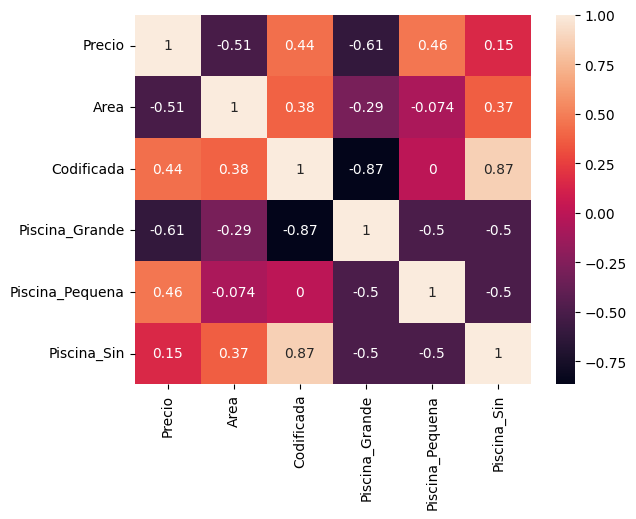

In [8]:
import seaborn as sns
sns.heatmap(datos1.corr(), annot=True)   

In [9]:
pd.get_dummies(datos, columns=['Piscina'], drop_first=True)


,Precio,Area,Codificada,Piscina_Pequena,Piscina_Sin
0,12,3,0,0,0
1,15,4,2,0,1
2,25,1,1,1,0
3,11,6,1,1,0
4,16,5,2,0,1
5,7,3,0,0,0


In [10]:
!pip install statsmodels

You should consider upgrading via the '/root/venv/bin/python -m pip install --upgrade pip' command.


In [11]:
import statsmodels.formula.api as smf

In [12]:
datos.columns

Index(['Precio', 'Area', 'Piscina', 'Codificada'], dtype='object')

In [13]:
modelo1=smf.ols("Precio~ Area + Piscina ", data=datos).fit()
modelo1.summary()

/root/venv/lib/python3.9/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Precio   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.741
Method:                 Least Squares   F-statistic:                     5.757
Date:                Sat, 05 Nov 2022   Prob (F-statistic):              0.152
Time:                        20:04:35   Log-Likelihood:                -12.041
No. Observations:                   6   AIC:                             32.08
Df Residuals:                       2   BIC:                             31.25
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             17.4615      3.404      5.129      0.036       2.813      32.110
Piscina[T.Pequena]     9.8269      3.148      3.122      0.089      -3.717      23.370
Piscina[T.Sin]         9.9808      3.377      2.956      0.098      -4.549      24.511
Area                  -2.6538      0.865     -3.069      0.092      -6.375       1.067
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   2.448
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.494
Skew:                          -0.000   Prob(JB):                        0.781
Kurtosis:                       1.594   Cond. No.                         13.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Ejemplo:

Utilizar la base de dato `Cars93` 
El objetivo es ajustar el siguiente modelo para explicar el precio del auto en función del tamaño del motor y del tipo de auto, es decir, el objetivo es ajustar el siguiente modelo.



In [14]:
Cars93=pd.read_csv("../datos/Cars93.csv")
Cars93=Cars93.drop("Unnamed: 0" ,axis=1)
Cars93

,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,DriveTrain,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,Acura,Integra,Small,12.9,15.9,18.8,25,31,None,Front,...,5,177,102,68,37,26.5,11.0,2705,non-USA,Acura Integra
1,Acura,Legend,Midsize,29.2,33.9,38.7,18,25,Driver & Passenger,Front,...,5,195,115,71,38,30.0,15.0,3560,non-USA,Acura Legend
2,Audi,90,Compact,25.9,29.1,32.3,20,26,Driver only,Front,...,5,180,102,67,37,28.0,14.0,3375,non-USA,Audi 90
3,Audi,100,Midsize,30.8,37.7,44.6,19,26,Driver & Passenger,Front,...,6,193,106,70,37,31.0,17.0,3405,non-USA,Audi 100
4,BMW,535i,Midsize,23.7,30.0,36.2,22,30,Driver only,Rear,...,4,186,109,69,39,27.0,13.0,3640,non-USA,BMW 535i
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,Volkswagen,Eurovan,Van,16.6,19.7,22.7,17,21,None,Front,...,7,187,115,72,38,34.0,NaN,3960,non-USA,Volkswagen Eurovan
89,Volkswagen,Passat,Compact,17.6,20.0,22.4,21,30,None,Front,...,5,180,103,67,35,31.5,14.0,2985,non-USA,Volkswagen Passat
90,Volkswagen,Corrado,Sporty,22.9,23.3,23.7,18,25,None,Front,...,4,159,97,66,36,26.0,15.0,2810,non-USA,Volkswagen Corrado
91,Volvo,240,Compact,21.8,22.7,23.5,21,28,Driver only,Rear,...,5,190,104,67,37,29.5,14.0,2985,non-USA,Volvo 240


In [15]:
_dntk.DeepnoteChart(Cars93, '{"mark":{"type":"bar","tooltip":true},"$schema":"https://vega.github.io/schema/vega-lite/v4.json","encoding":{"x":{"sort":null,"type":"nominal","field":"Type","scale":{"type":"linear","zero":false}},"y":{"sort":null,"type":"nominal","field":"","scale":{"type":"linear","zero":true}},"color":{"sort":null,"type":"nominal","field":"","scale":{"type":"linear","zero":false}}}}', filters='[]')

$$
\begin{aligned}
\mu_i = &\beta_0 + \beta_1 EngSize_i + \beta_2 TypeC_i + \beta_3 TypeS_i + \\
&\beta_4 TypeM_i + \beta_5 TypeL_i + \beta_6 TypeV_i, \\
\end{aligned}
$$

In [16]:
Cars93.Type.unique()

array(['Small', 'Midsize', 'Compact', 'Large', 'Sporty', 'Van'],
      dtype=object)

In [17]:
modelo_cars=smf.ols('Price ~ EngineSize + Type', data=Cars93).fit()
modelo_cars.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     14.30
Date:                Sat, 05 Nov 2022   Prob (F-statistic):           3.07e-11
Time:                        20:04:35   Log-Likelihood:                -310.19
No. Observations:                  93   AIC:                             634.4
Df Residuals:                      86   BIC:                             652.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           7.4387      3.133      2.374      0.020       1.210      13.667
Type[T.Large]      -2.5909      3.465     -0.748      0.457      -9.480       4.298
Type[T.Midsize]     5.6420      2.459      2.295      0.024       0.754      10.530
Type[T.Small]      -4.6444      2.484     -1.870      0.065      -9.582       0.293
Type[T.Sporty]      0.4335      2.593      0.167      0.868      -4.721       5.588
Type[T.Van]        -3.1274      3.099     -1.009      0.316      -9.288       3.033
EngineSize          4.6215      1.110      4.164      0.000       2.415       6.828
==============================================================================
Omnibus:                       46.037   Durbin-Watson:                   1.385
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              168.112
Skew:                           1.601   Prob(JB):                     3.12e-37
Kurtosis:                       8.756   Cond. No.                         19.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [18]:
 modelo_cars1=smf.ols('Price ~ EngineSize + C(Type, Treatment(reference="Small")) ', data=Cars93).fit()
modelo_cars1.summary()
 


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     14.30
Date:                Sat, 05 Nov 2022   Prob (F-statistic):           3.07e-11
Time:                        20:04:35   Log-Likelihood:                -310.19
No. Observations:                  93   AIC:                             634.4
Df Residuals:                      86   BIC:                             652.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
====================================================================================================================
                                                       coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                            2.7943      2.348      1.190      0.237      -1.874       7.462
C(Type, Treatment(reference="Small"))[T.Compact]     4.6444      2.484      1.870      0.065      -0.293       9.582
C(Type, Treatment(reference="Small"))[T.Large]       2.0535      3.916      0.524      0.601      -5.732       9.839
C(Type, Treatment(reference="Small"))[T.Midsize]    10.2864      2.700      3.810      0.000       4.919      15.654
C(Type, Treatment(reference="Small"))[T.Sporty]      5.0779      2.634      1.928      0.057      -0.159      10.315
C(Type, Treatment(reference="Small"))[T.Van]         1.5170      3.332      0.455      0.650      -5.107       8.141
EngineSize                                           4.6215      1.110      4.164      0.000       2.415       6.828
==============================================================================
Omnibus:                       46.037   Durbin-Watson:                   1.385
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              168.112
Skew:                           1.601   Prob(JB):                     3.12e-37
Kurtosis:                       8.756   Cond. No.                         23.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Cómo se interpretan los coeficientes?

- Para cada tipo de auto, si el tamaño del motor se pudiera aumentar en 1 litro, se espera que el precio promedio aumente en 4.621 miles de dólares.
- Si tenemos dos autos, uno small y otro compacto, ambos con el mismo tamaño del motor, se espera que el precio promedio del compacto sea 4.644 miles de dólares mayor con respecto al auto small.
- Si comparamos un auto small y uno midsize, ambos con el mismo tamaño del motor, es de esperarse que el precio promedio del auto midsize sea 10.286 miles de dólares más que el small.
- Dos autos con el mismo tamaño del motos, uno de tipo sporty y otro de tipo large, se espera que el de tipo sporty tenga un precio promedio de 3.025 miles de dólares más que el large 

<br><a href="#linealidad">1. Linealidad</a>
<br><a href="#media">2. Media de residuos</a>
<br><a href="#homo">3. Comprobar la homocedasticidad</a>
<br><a href="#normal">4. Comprobar la normalidad de los términos/residuales de error</a>
<br><a href="#auto">5. Sin autocorrelación de residuos</a>
<br><a href="#multico">6. Sin multicolinealidad perfecta</a>
<br><a href="#otro">7. Otros modelos para comparar</a>

In [19]:
import seaborn as sns

In [20]:
df = pd.read_csv('../datos/Advertising.csv',index_col='Unnamed: 0')
df

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9
...,...,...,...,...
196,38.2,3.7,13.8,7.6
197,94.2,4.9,8.1,9.7
198,177.0,9.3,6.4,12.8
199,283.6,42.0,66.2,25.5


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 7.8 KB


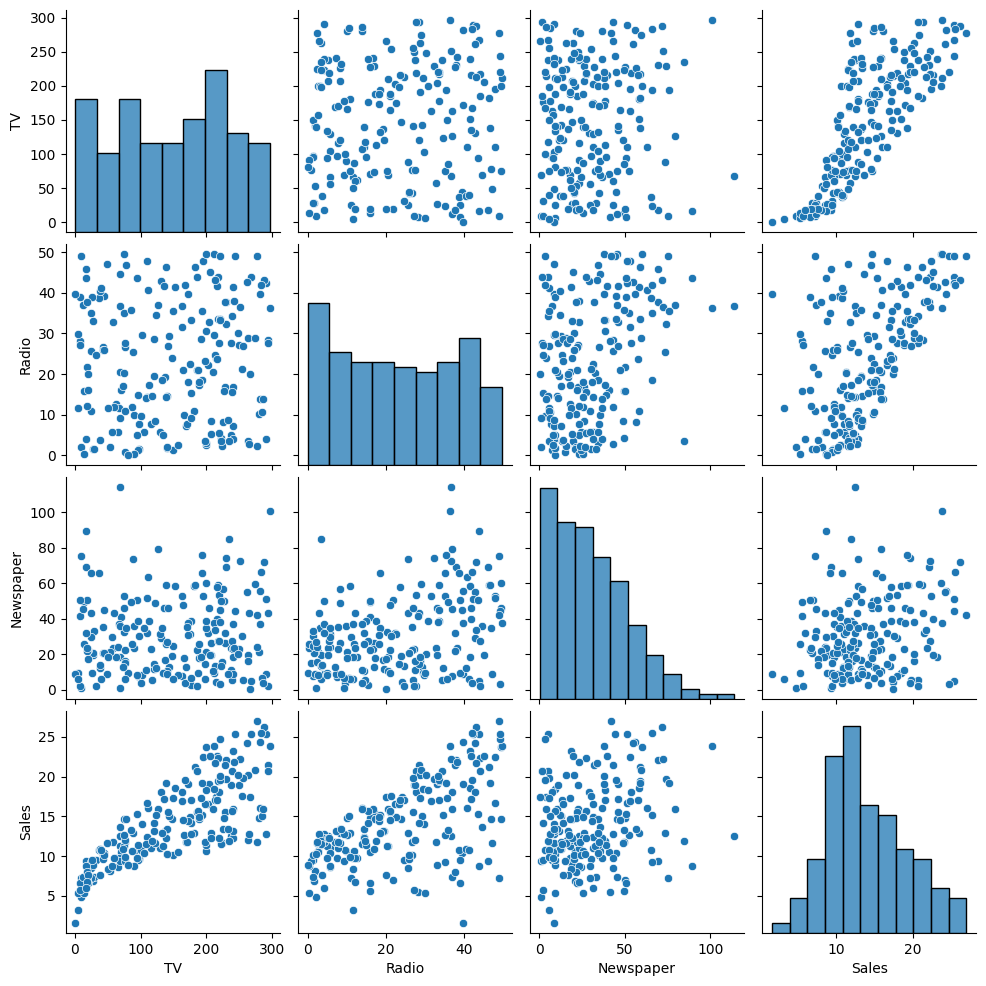

In [22]:
p = sns.pairplot(df)

### Supuestos para regresión lineal

### <a id="linealidad">1. Linealidad</a>

##### La regresión lineal necesita que la relación entre las variables independientes y dependientes sea lineal. Usemos un gráfico de pares para verificar la relación de las variables independientes con la variable Ventas

/shared-libs/python3.9/py/lib/python3.9/site-packages/seaborn/axisgrid.py:2095: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


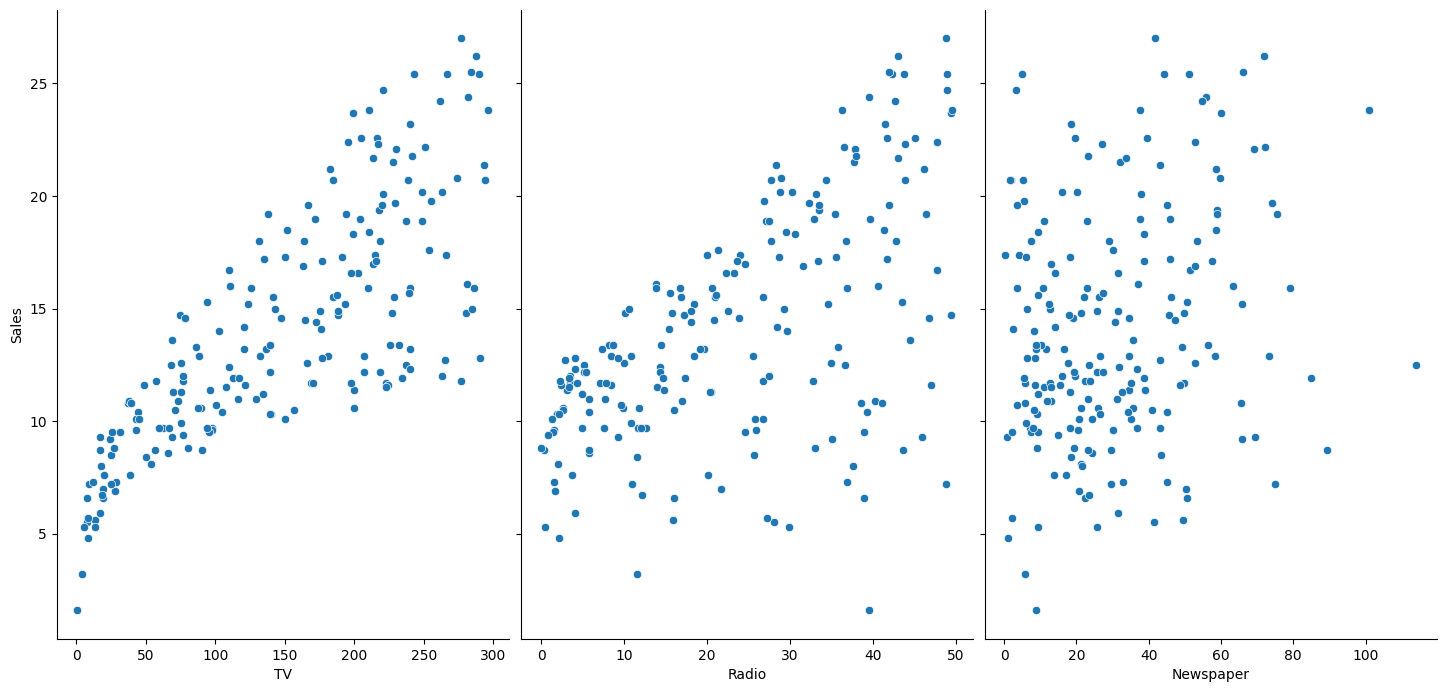

In [23]:
# visualize the relationship between the features and the response using scatterplots
p = sns.pairplot(df, x_vars=['TV','Radio','Newspaper'], y_vars='Sales', size=7, aspect=0.7)

### visualizar la relación entre las características y la respuesta usando diagramas de dispersión


### El resto de las suposiciones requieren que realicemos la regresión antes de que podamos verificarlas. 

In [24]:
df.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [40]:
modelo2=smf.ols("Sales ~ TV+ Radio + Newspaper ", data=df).fit()
modelo2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Sat, 05 Nov 2022   Prob (F-statistic):           1.58e-96
Time:                        20:11:20   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
Radio          0.1885      0.009     21.893      0.000       0.172       0.206
Newspaper     -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""


## <a id="media">2. Media de residuos</a>

##### Los residuos, como sabemos, son las diferencias entre el valor real y el valor predicho. Uno de los supuestos de la regresión lineal es que la media de los residuos debe ser cero

In [41]:
residuales=modelo2.resid
residuales

1      1.576026
2     -1.937855
3     -3.007671
4      0.902170
5     -0.288672
         ...   
196    2.229658
197    1.534688
198    0.014079
199    1.732679
200   -1.773196
Length: 200, dtype: float64

In [42]:
residuales.mean()

8.171241461241152e-16

In [43]:
residuales.describe()

count    2.000000e+02
mean     8.171241e-16
std      1.672757e+00
min     -8.827687e+00
25%     -8.908135e-01
50%      2.418018e-01
75%      1.189319e+00
max      2.829223e+00
dtype: float64

In [46]:
residuales.sort_values().head(10)

131   -8.827687
6     -5.278348
179   -4.210997
36    -4.206826
127   -3.977174
26    -3.610039
79    -3.513314
76    -3.158322
159   -3.084199
57    -3.027713
dtype: float64

In [51]:
df.loc[[131,6,179,36],]

,TV,Radio,Newspaper,Sales
131,0.7,39.6,8.7,1.6
6,8.7,48.9,75.0,7.2
179,276.7,2.3,23.7,11.8
36,290.7,4.1,8.5,12.8


In [74]:
modelo2.predict()[130]

10.427687101769529

In [53]:
import plotly.express as px
px.box(df, points="all")

## <a id="homo">3. Homocedasticidad</a>

#### La homocedasticidad significa que los residuos tienen una varianza igual o casi igual a lo largo de la línea de regresión. Al graficar los términos de error con los términos predichos, podemos verificar que no debería haber ningún patrón en los términos de error.

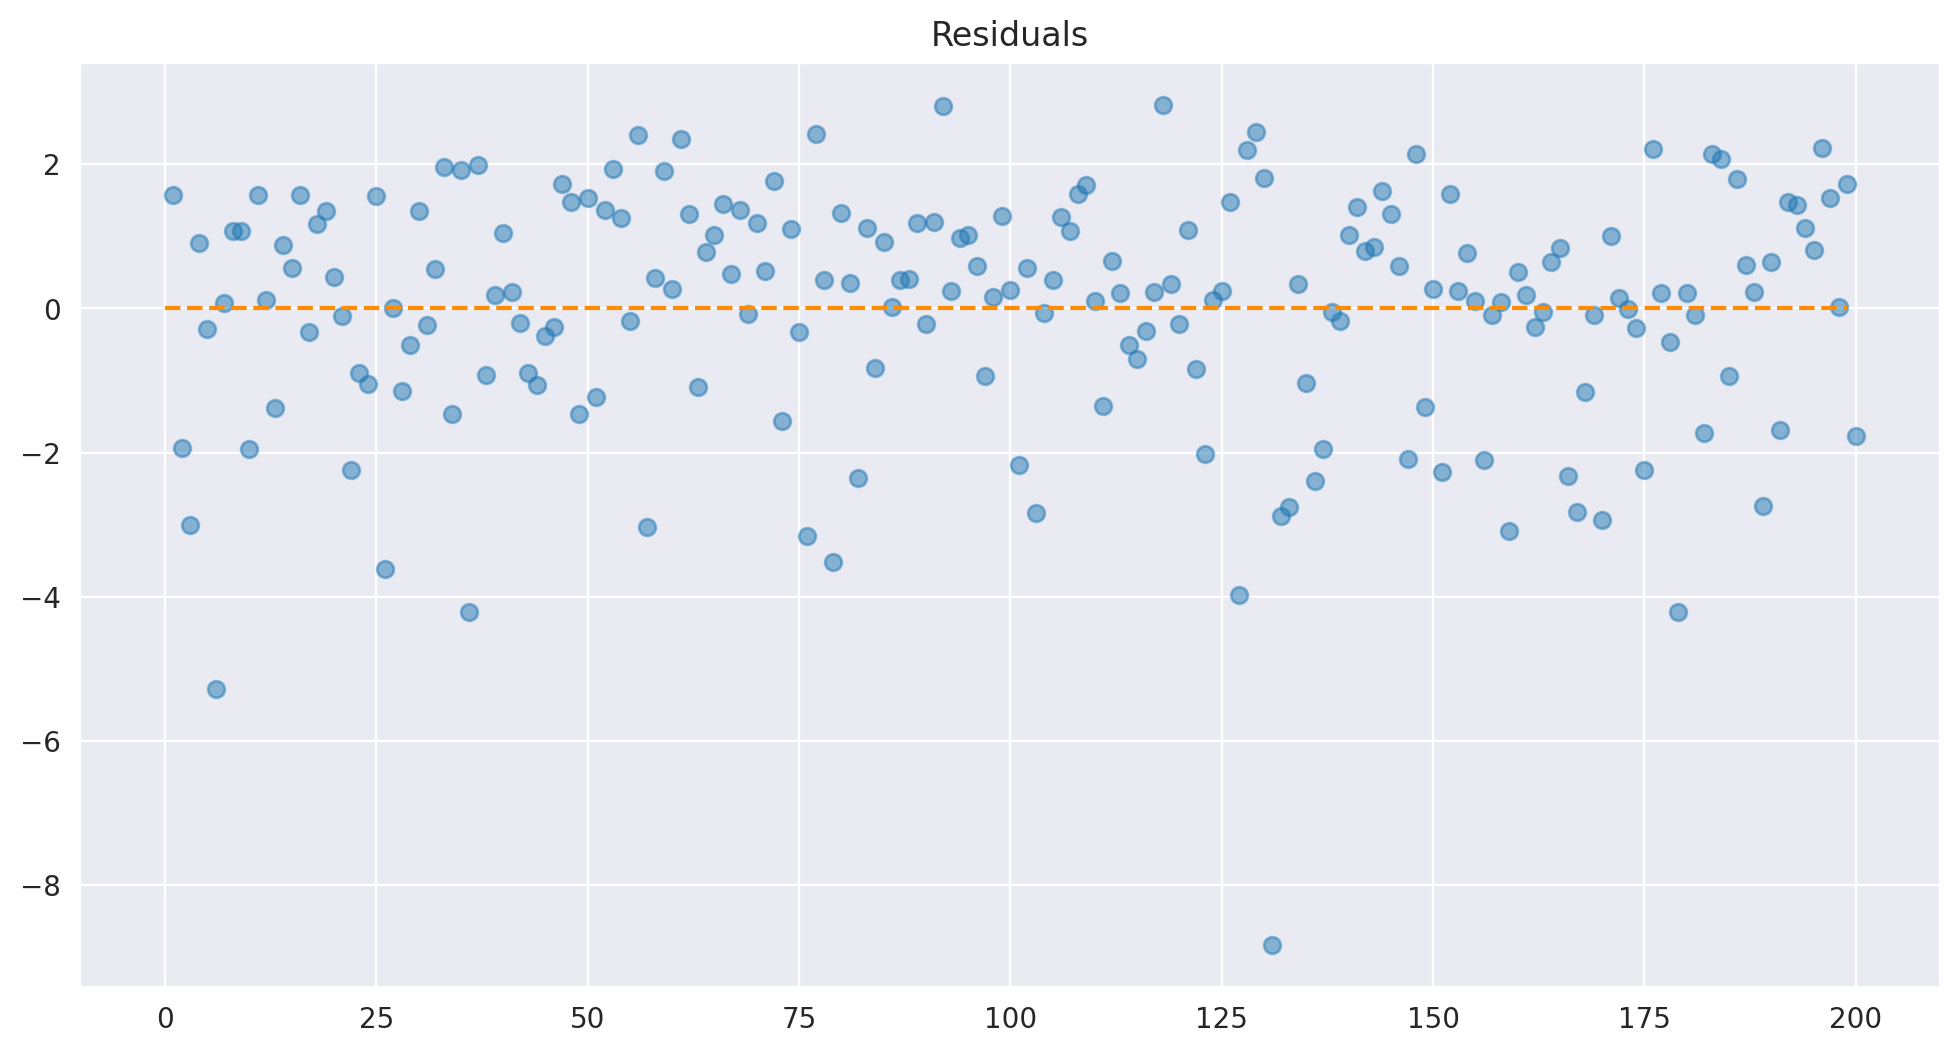

In [56]:
import matplotlib.pyplot as plt

plt.subplots(figsize=(12, 6))
ax = plt.subplot(111)  
plt.scatter(x=residuales.index, y=residuales, alpha=0.5)
plt.plot(np.repeat(0,residuales.index.max()), color='darkorange', linestyle='--')
plt.title('Residuals')
plt.show()  



In [58]:
%matplotlib inline
%config InlineBackend.figure_format ='retina'
import seaborn as sns 
import matplotlib.pyplot as plt
import statsmodels.stats.api as sms
sns.set_style('darkgrid')
sns.mpl.rcParams['figure.figsize'] = (15.0, 9.0)

def homoscedasticity_test(model):
    '''
    Function for testing the homoscedasticity of residuals in a linear regression model.
    It plots residuals and standardized residuals vs. fitted values and runs Breusch-Pagan and Goldfeld-Quandt tests.
    
    Args:
    * model - fitted OLS model from statsmodels
    '''
    fitted_vals = model.predict()
    resids = model.resid
    resids_standardized = model.get_influence().resid_studentized_internal

    fig, ax = plt.subplots(1,2)

    sns.regplot(x=fitted_vals, y=resids, lowess=True, ax=ax[0], line_kws={'color': 'red'})
    ax[0].set_title('Residuals vs Fitted', fontsize=16)
    ax[0].set(xlabel='Fitted Values', ylabel='Residuals')

    sns.regplot(x=fitted_vals, y=np.sqrt(np.abs(resids_standardized)), lowess=True, ax=ax[1], line_kws={'color': 'red'})
    ax[1].set_title('Scale-Location', fontsize=16)
    ax[1].set(xlabel='Fitted Values', ylabel='sqrt(abs(Residuals))')

    bp_test = pd.DataFrame(sms.het_breuschpagan(resids, model.model.exog), 
                           columns=['value'],
                           index=['Lagrange multiplier statistic', 'p-value', 'f-value', 'f p-value'])

    gq_test = pd.DataFrame(sms.het_goldfeldquandt(resids, model.model.exog)[:-1],
                           columns=['value'],
                           index=['F statistic', 'p-value'])

    print('\n Breusch-Pagan test ----')
    print(bp_test)
    print('\n Goldfeld-Quandt test ----')
    print(gq_test)
    print('\n Residuals plots ----')




 Breusch-Pagan test ----
                                  value
Lagrange multiplier statistic  5.132872
p-value                        0.162322
f-value                        1.720904
f p-value                      0.163999

 Goldfeld-Quandt test ----
                value
F statistic  1.351683
p-value      0.070821

 Residuals plots ----


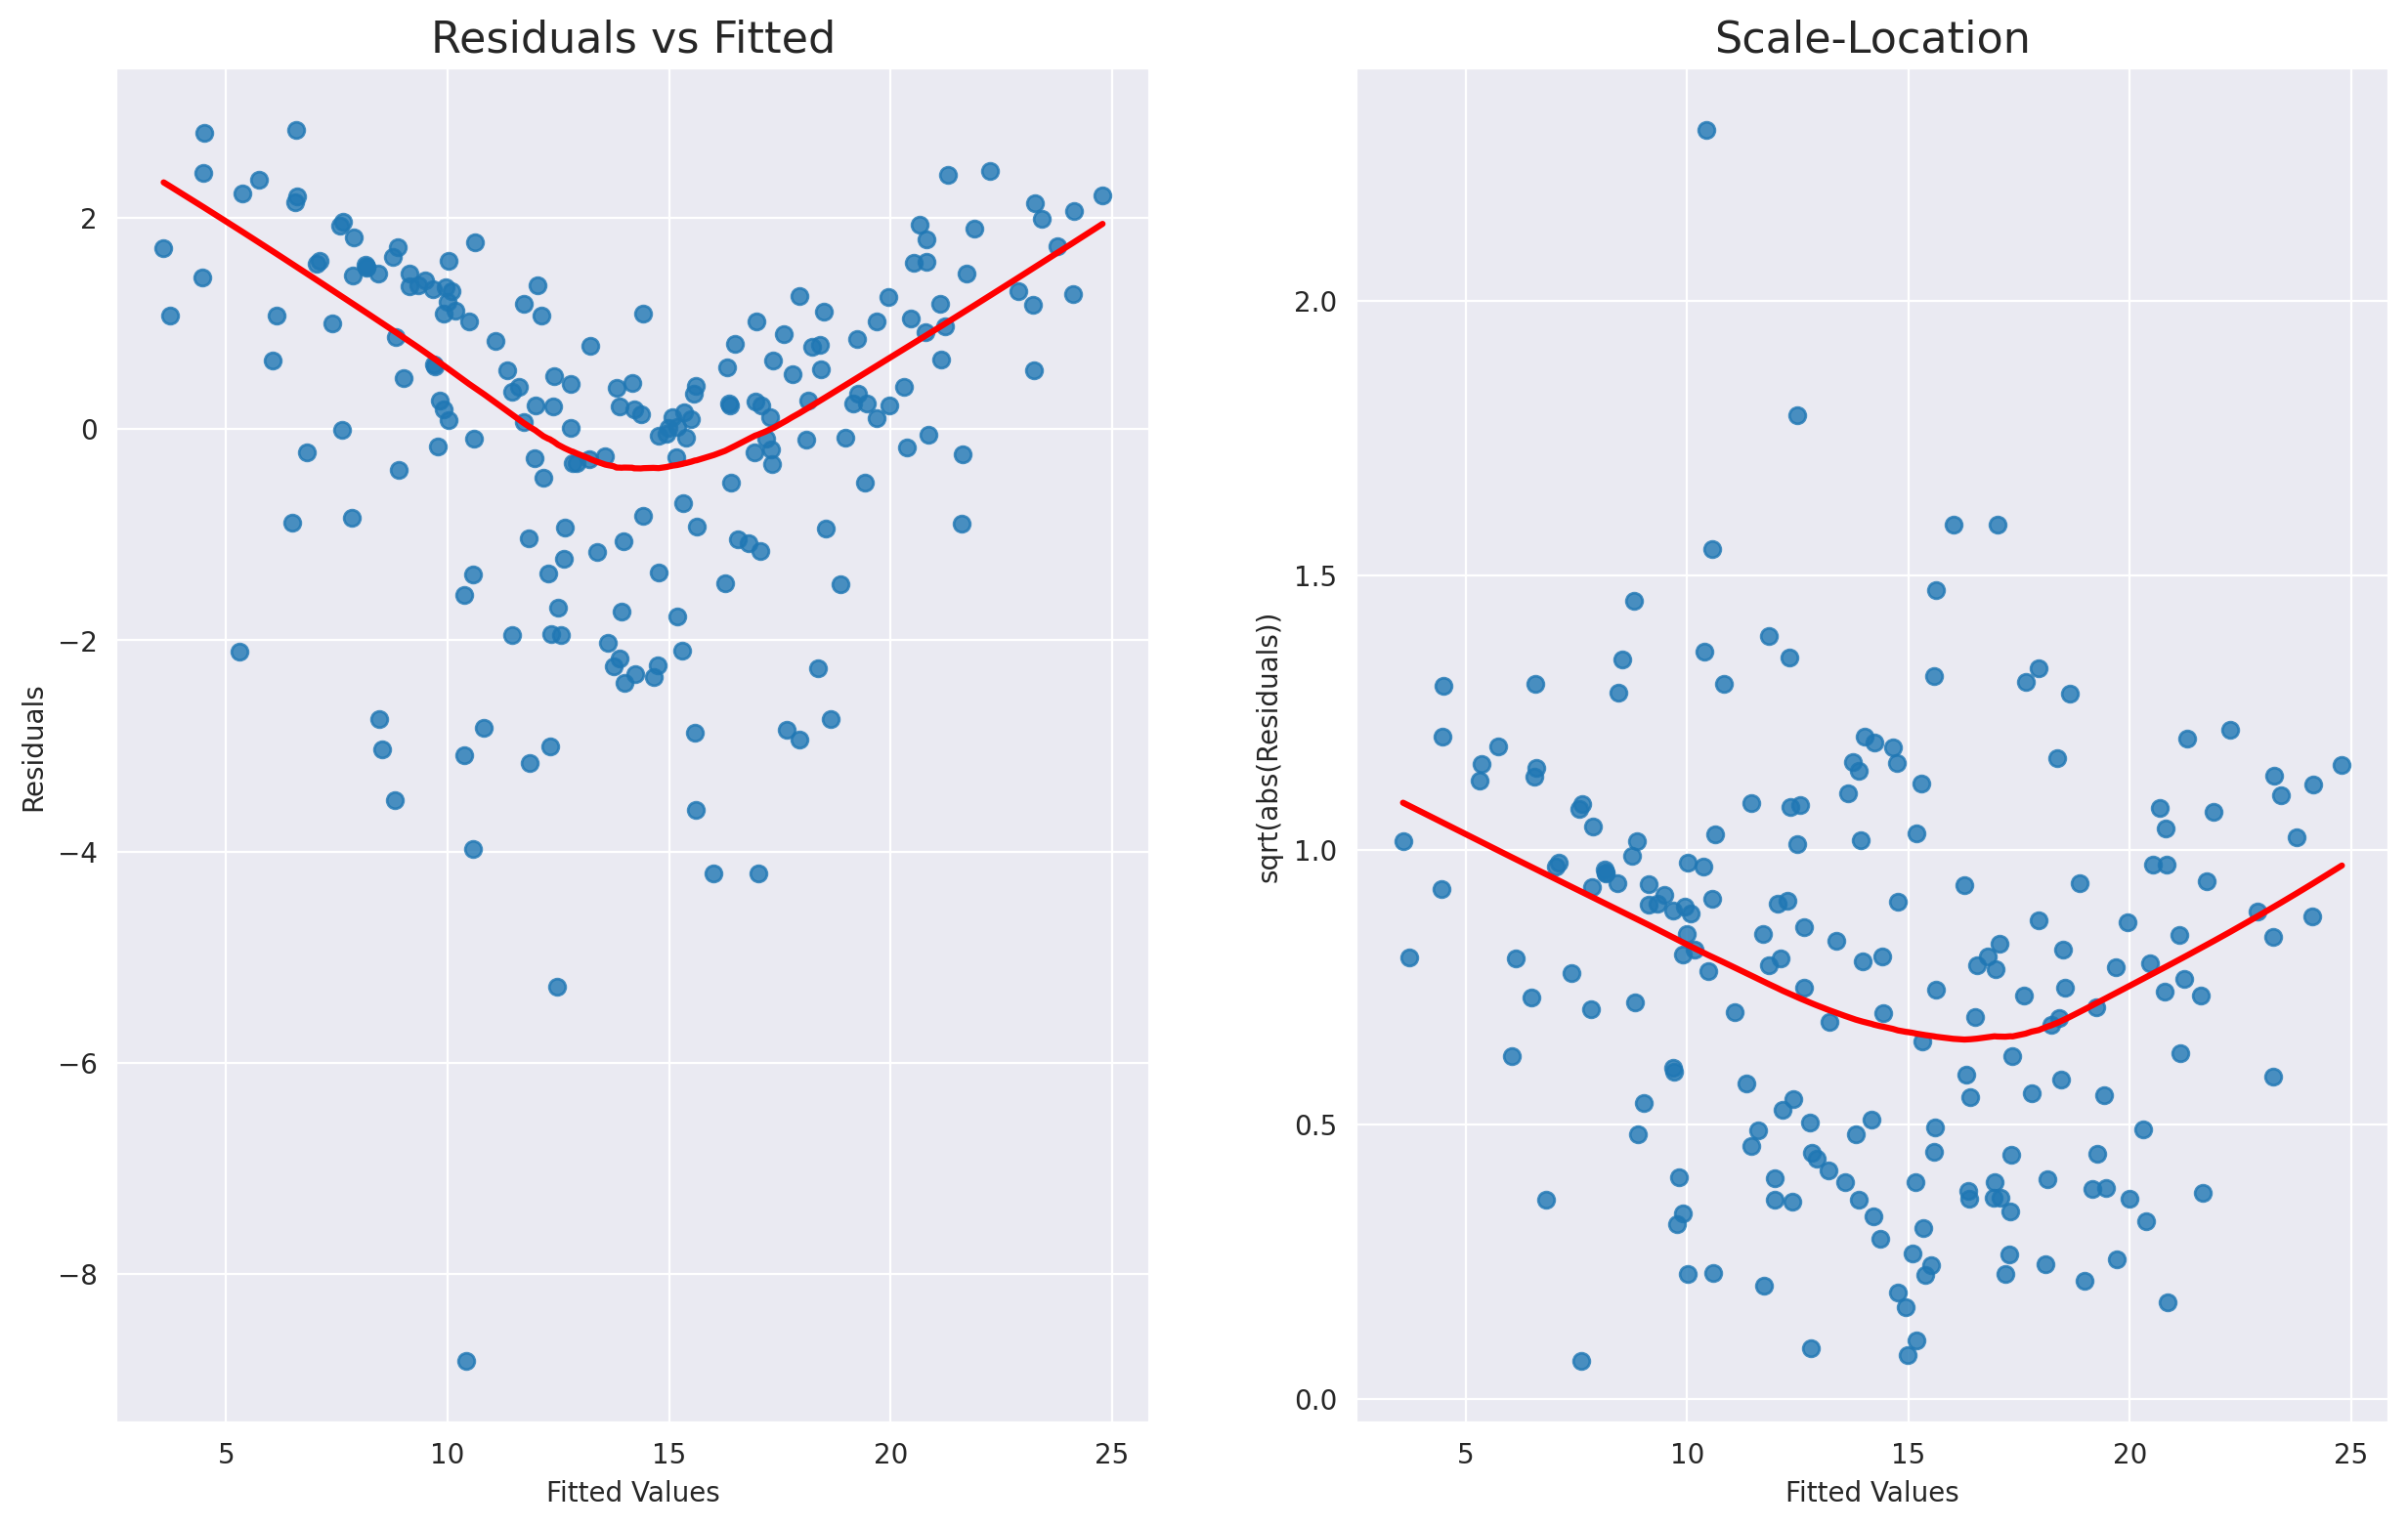

In [59]:
homoscedasticity_test(modelo2)

## Prueba Breusch-Pegan
 
* Hipótesis Nula: Los términos de error son homocedásticos
* Hipótesis alternativa: Los términos de error son heteroscedásticos.

## <a id="normal">4. Comprobar la normalidad de los términos/residuales de error</a>

/tmp/ipykernel_362/344196982.py:1: UserWarning:



`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751




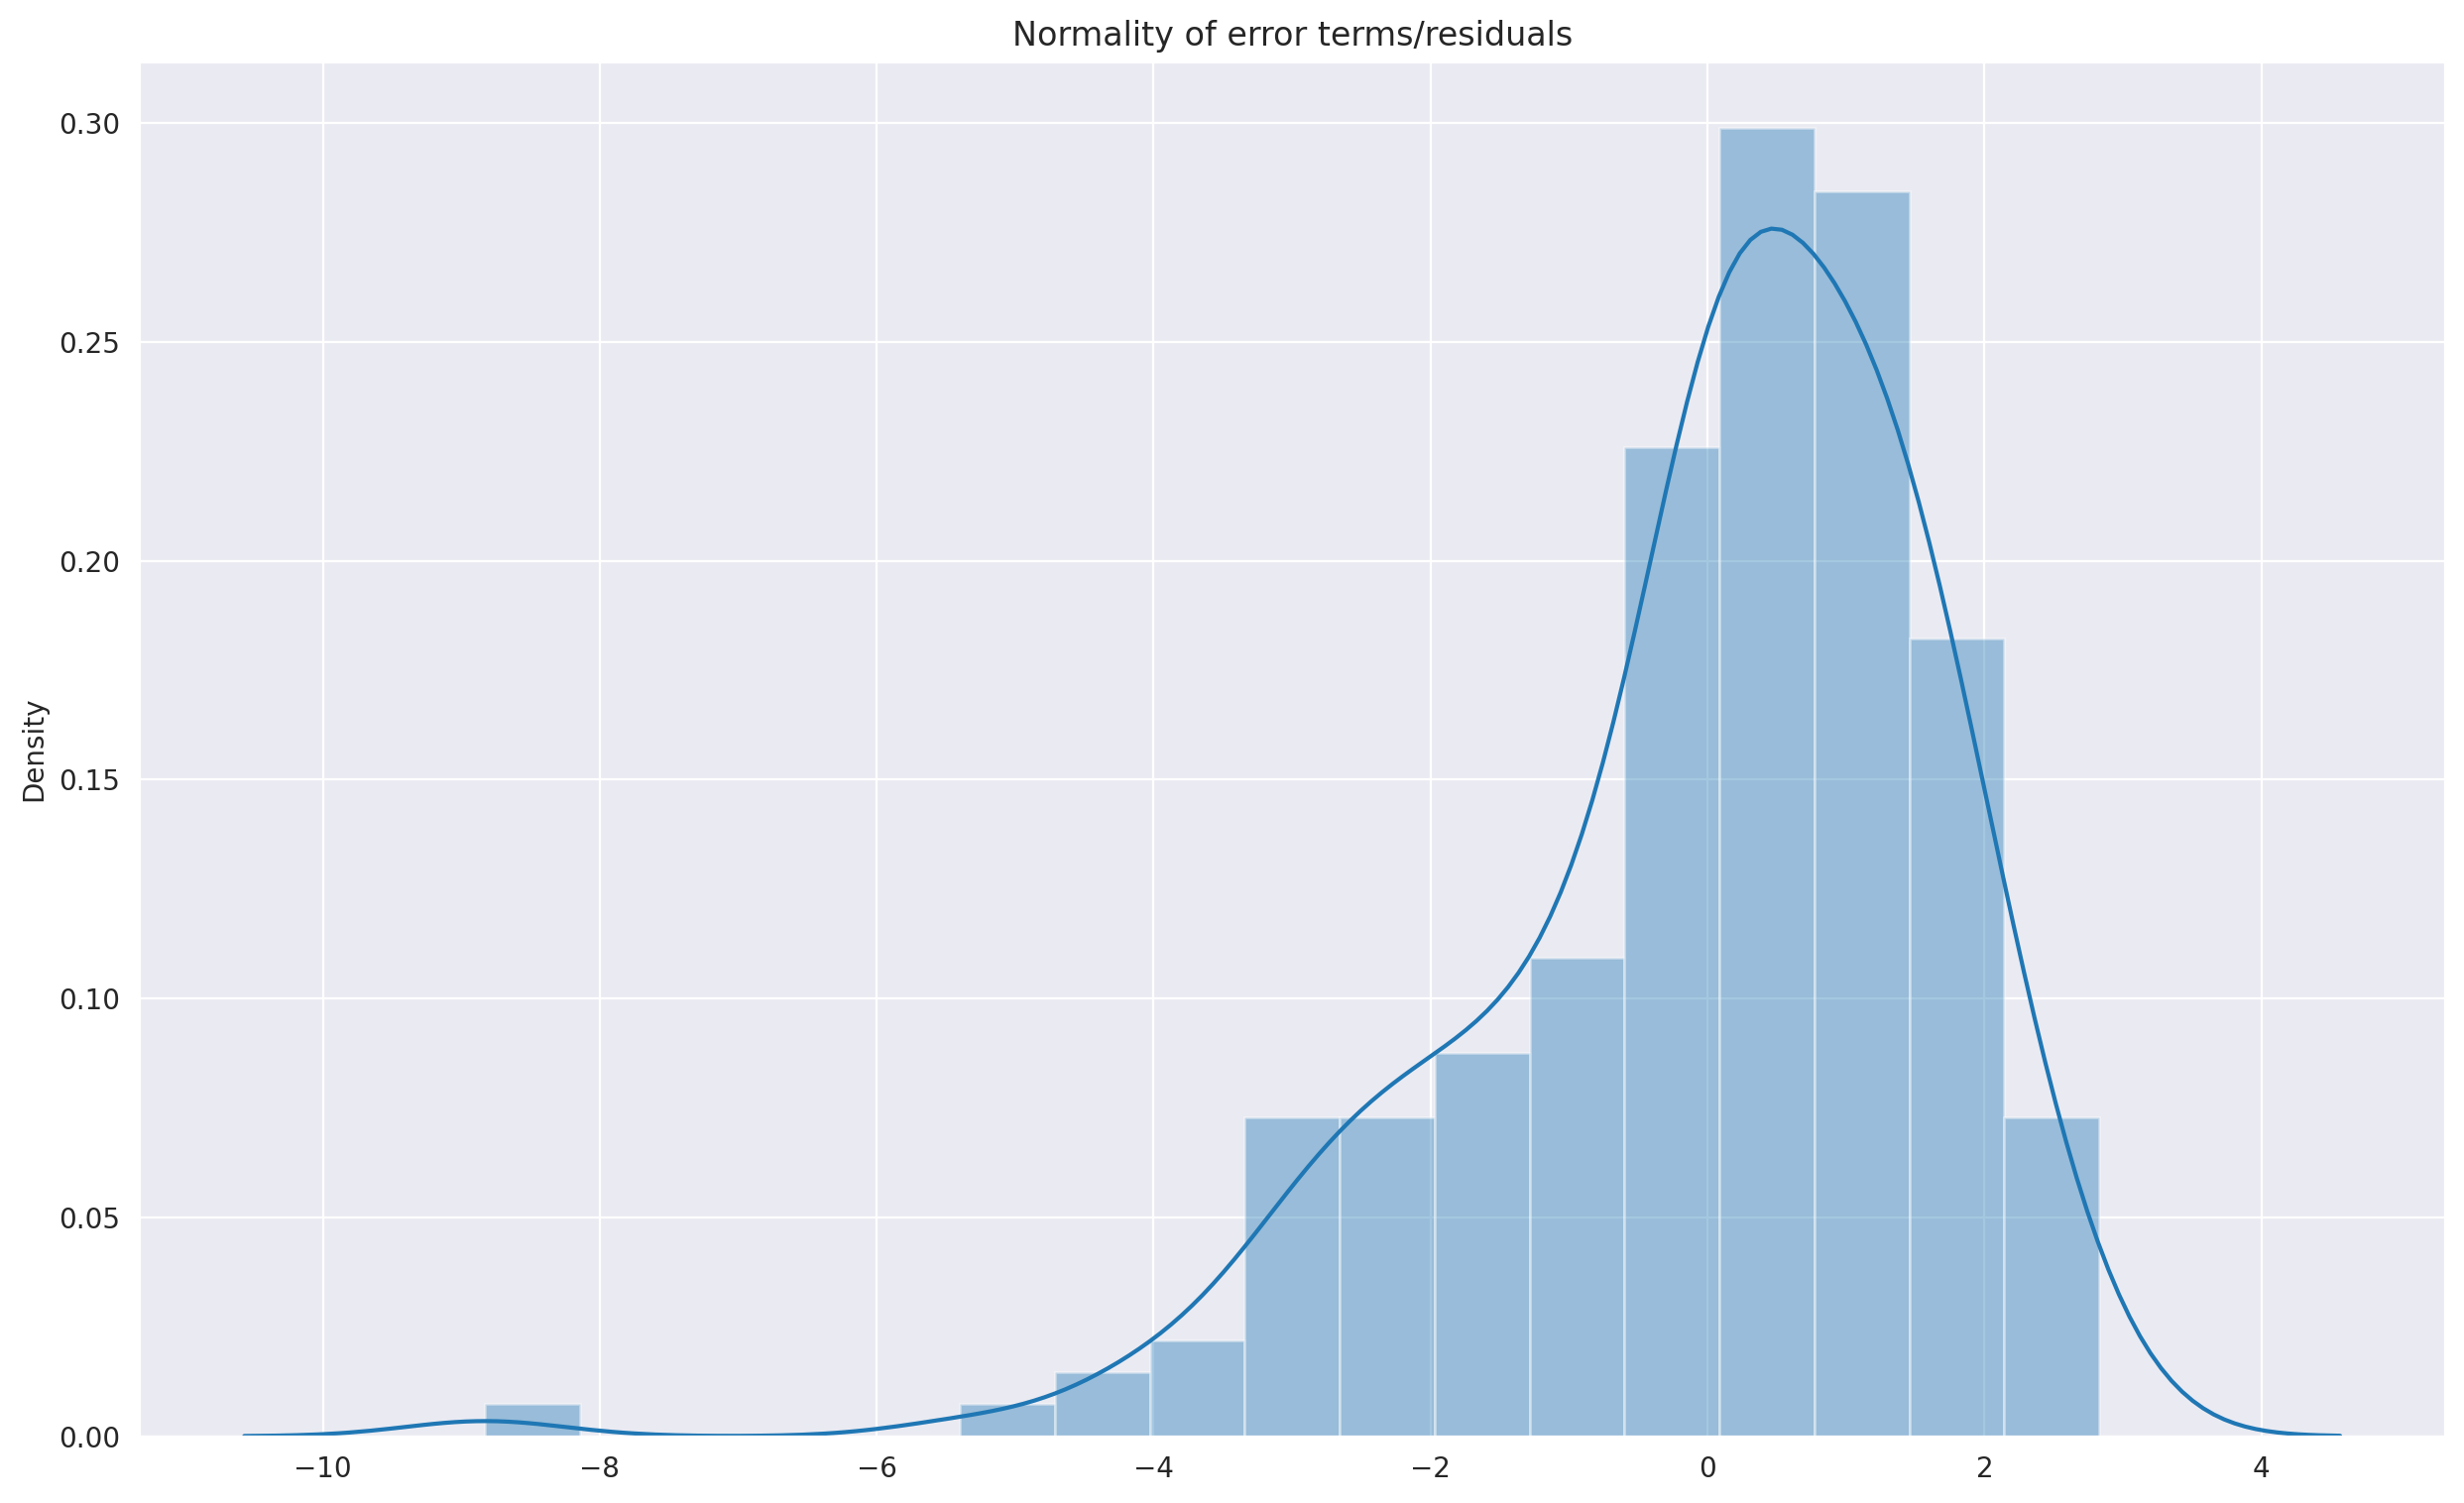

In [60]:
p = sns.distplot(residuales,kde=True)
p = plt.title('Normality of error terms/residuals')

- Los términos residuales tienen una distribución bastante normal para el número de puntos de prueba que tomamos. 
- Un sesgo también es visible desde la trama. 
- **Es muy difícil obtener curvas perfectas, distribuciones en datos de la vida real.**

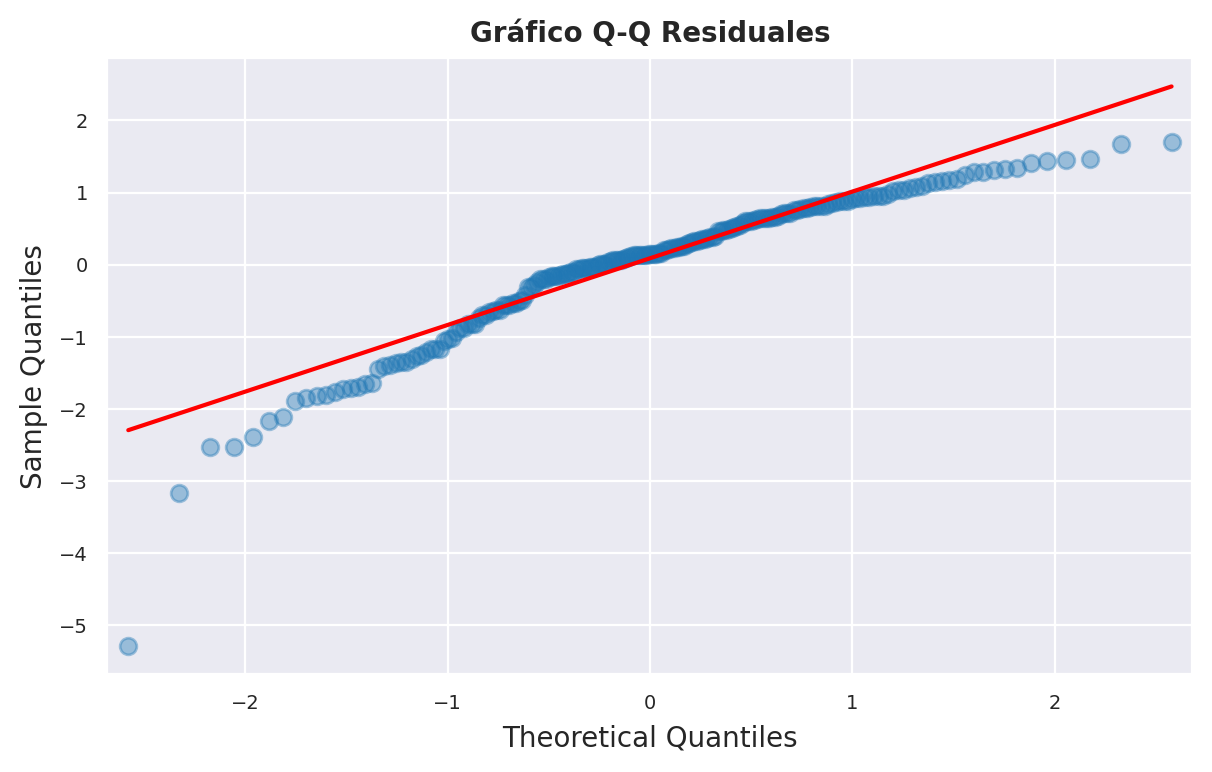

In [31]:
import statsmodels.api as sm
# Gráfico Q-Q
# ==============================================================================
fig, ax = plt.subplots(figsize=(7,4))
sm.qqplot(
    residuales,
    fit   = True,
    line  = 'q',
    alpha = 0.4,
    lw    = 2,
    ax    = ax
)
ax.set_title('Gráfico Q-Q Residuales', fontsize = 10,
             fontweight = "bold")
ax.tick_params(labelsize = 7)

In [75]:
from scipy import stats

# Shapiro-Wilk test
# ==============================================================================
shapiro_test = stats.shapiro(residuales)
shapiro_test

ShapiroResult(statistic=0.917664647102356, pvalue=3.938186221574824e-09)

## <a id="auto">5. Sin autocorrelación de residuos</a>

##### Cuando los residuos están autocorrelacionados, significa que el valor actual depende de los valores anteriores (históricos) y que existe un patrón inexplicable definido en la variable Y que aparece en los términos de error. Aunque es más evidente en los datos de series temporales.

##### En términos sencillos, la autocorrelación tiene lugar cuando hay un patrón en las filas de los datos. Esto es habitual en los datos de series de tiempo, ya que existe un patrón de tiempo para, por ejemplo. 


### No debe haber autocorrelación en los datos, por lo que los términos de error no deben formar ningún patrón.

El estadístico de Durbin-Watson


El estadístico de Durbin-Watson sirve para contrastar la hipótesis nula de “ausencia de autocorrelación en el modelo”, frente a la alternativa que plantea la existencia problemas de autocorrelación en el modelo, que vienen dados por una correlación serial de orden 1 (AR(1)), es decir:

$$H_0: \rho_1=0   \equiv   Ausencia de autocorrelación.$$

$$H_1: \rho_1\neq0 \equiv AR(1) \equiv    Problemas de autocorrelación.$$

El estadístico de Durbin-Watson se calcula mediante:

$$
d= \frac{\sum_{i=2}^n(e_t-e_{t-1})^2}{\sum_{i=1}^ne_t^2}
$$

Este estadístico toma valores cercanos a 2 cuando el modelo no tiene problemas de autocorrelación. Si existe una autocorrelación positiva entre las perturbaciones, el estadístico tendrá un valor cercano a 0, mientras que si la correlación es negativa será próximo a 4.

- $d \approx  2 \rightarrow$  No hay problemas de autocorrelación.
- $d \approx 0 \rightarrow$  Autocorrelación positiva.
- $d \approx  4 \rightarrow$  Autocorrelación negativa.


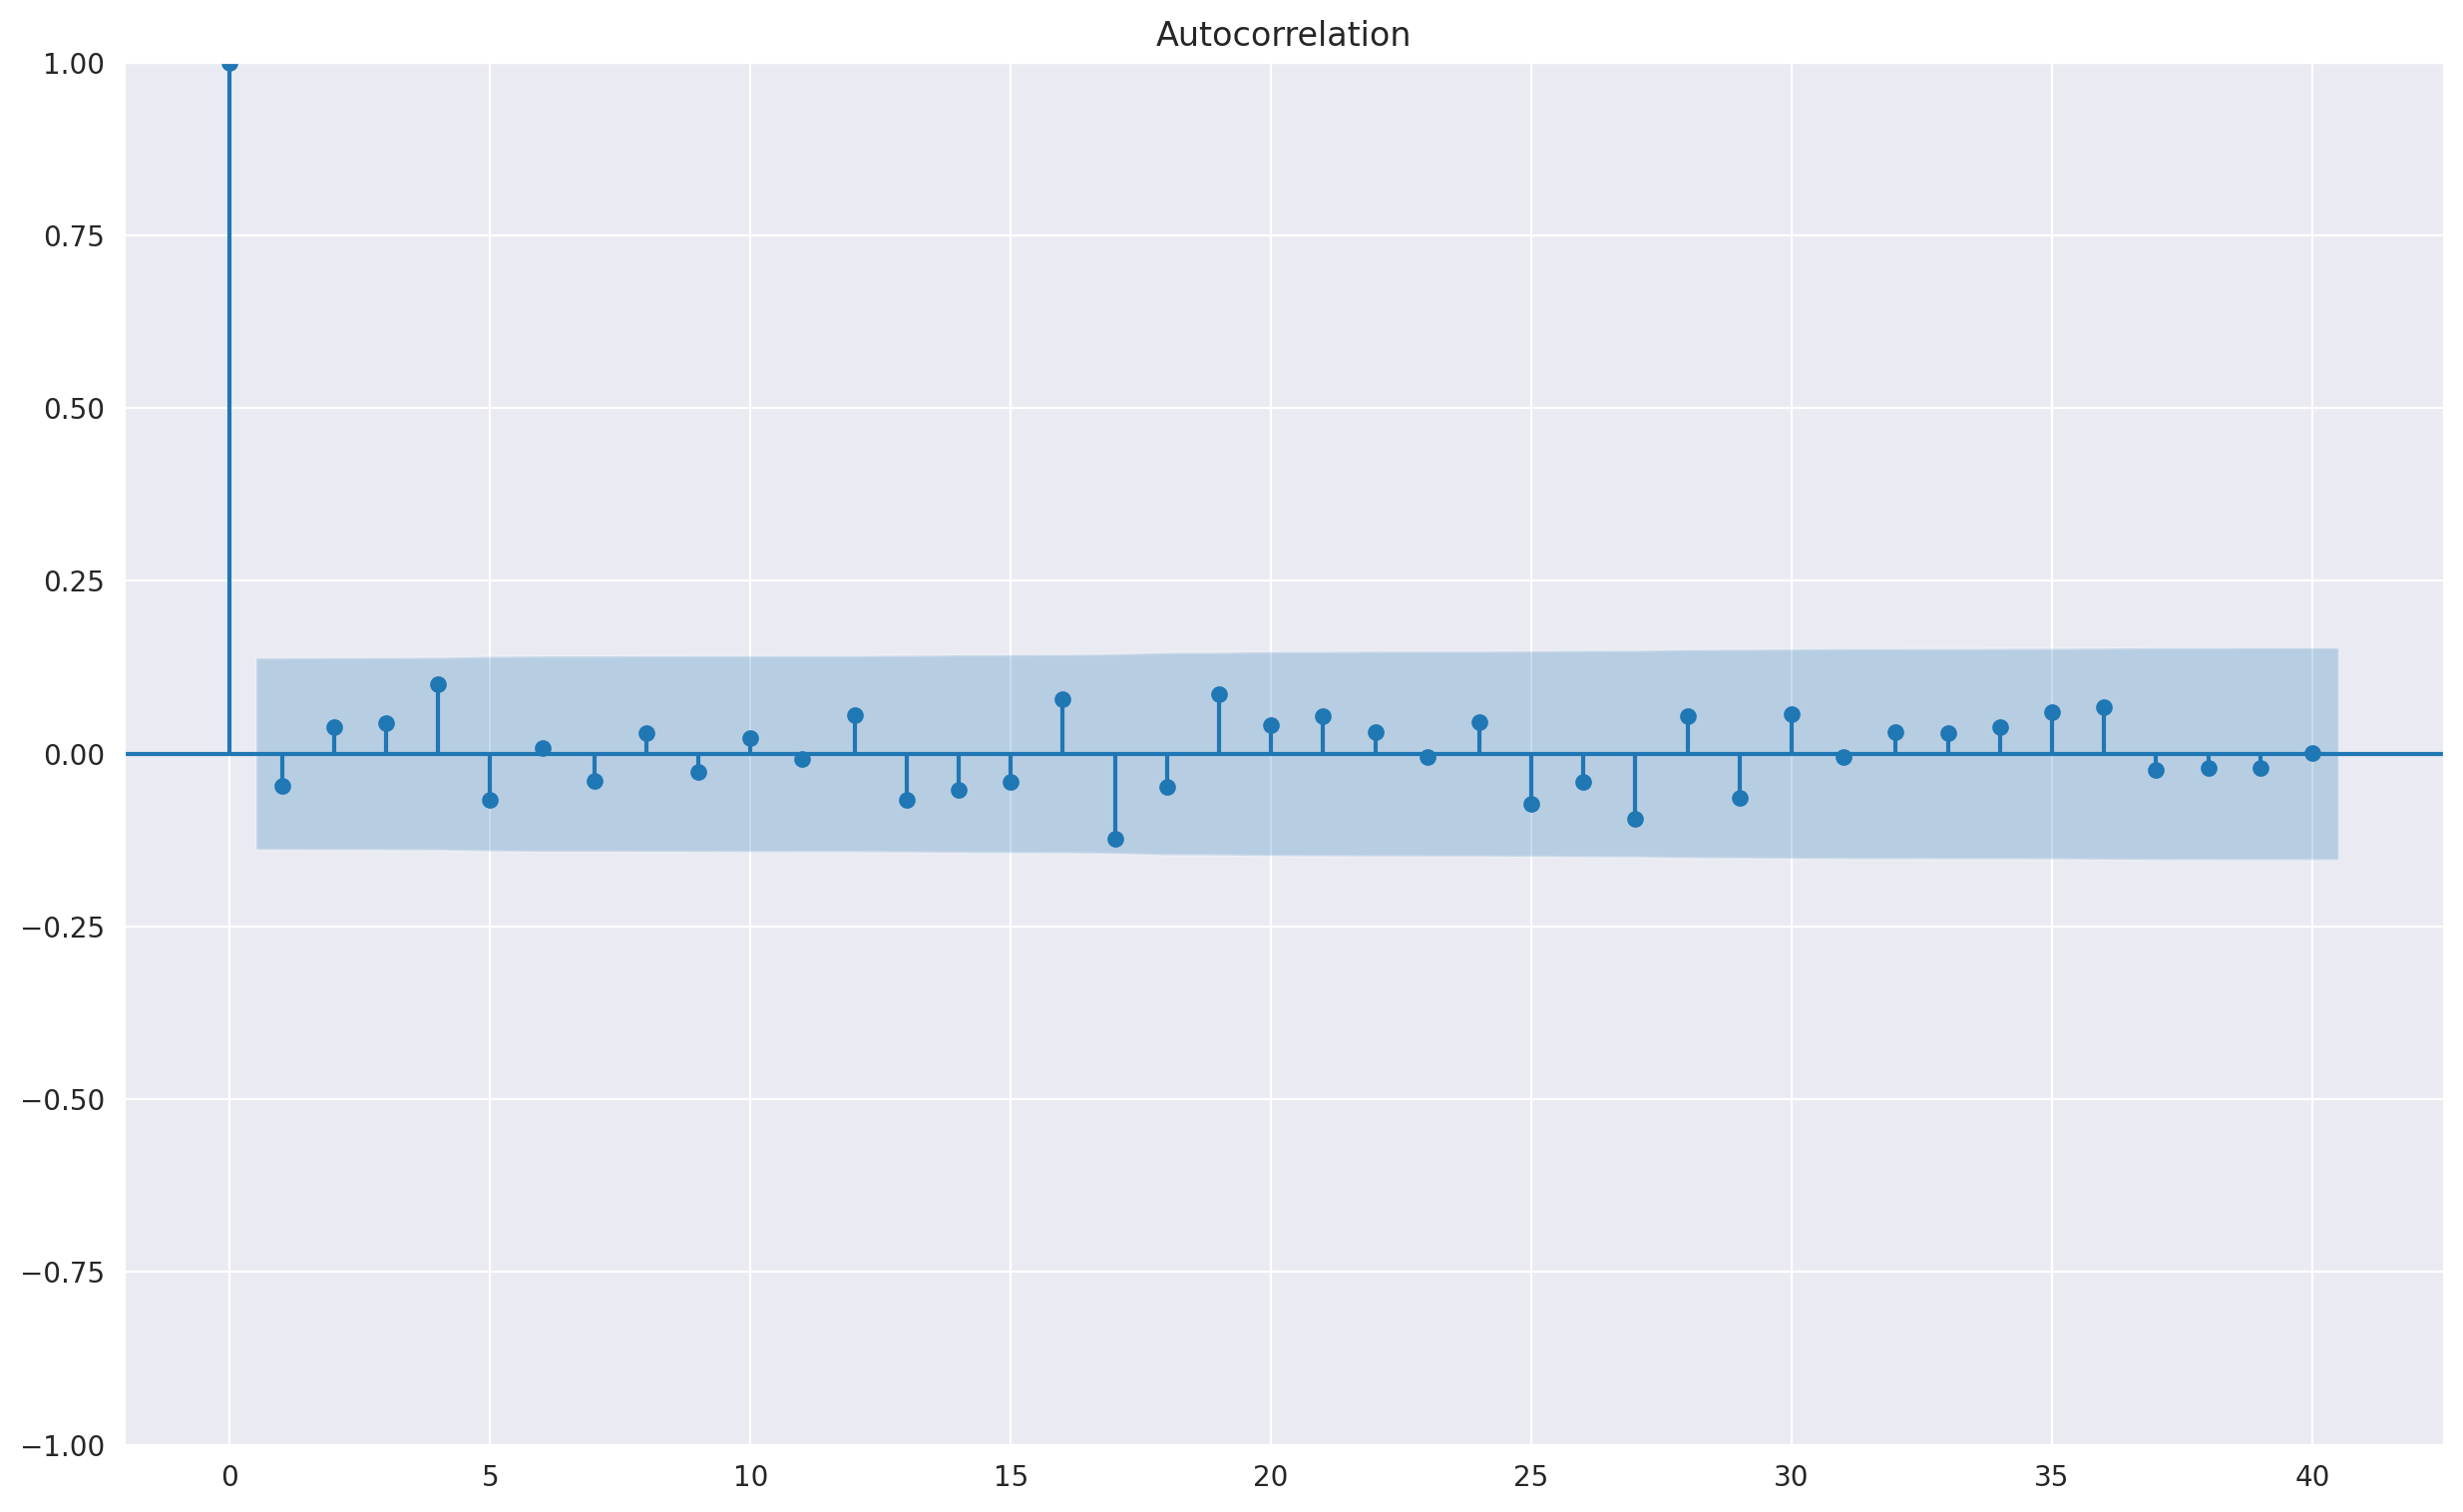

In [33]:
import statsmodels.tsa.api as smt

acf = smt.graphics.plot_acf(modelo2.resid, lags=40 , alpha=0.05)
acf.show()


## <a id="multico">6. Multicolinealidad</a>

##### En la regresión, la multicolinealidad se refiere al grado en que las variables independientes están correlacionadas. La multicolinealidad afecta los coeficientes y los valores p, pero no influye en las predicciones, la precisión de las predicciones y las estadísticas de bondad de ajuste. Si su objetivo principal es hacer predicciones y no necesita comprender el rol de cada variable independiente, no necesita reducir la multicolinealidad severa.

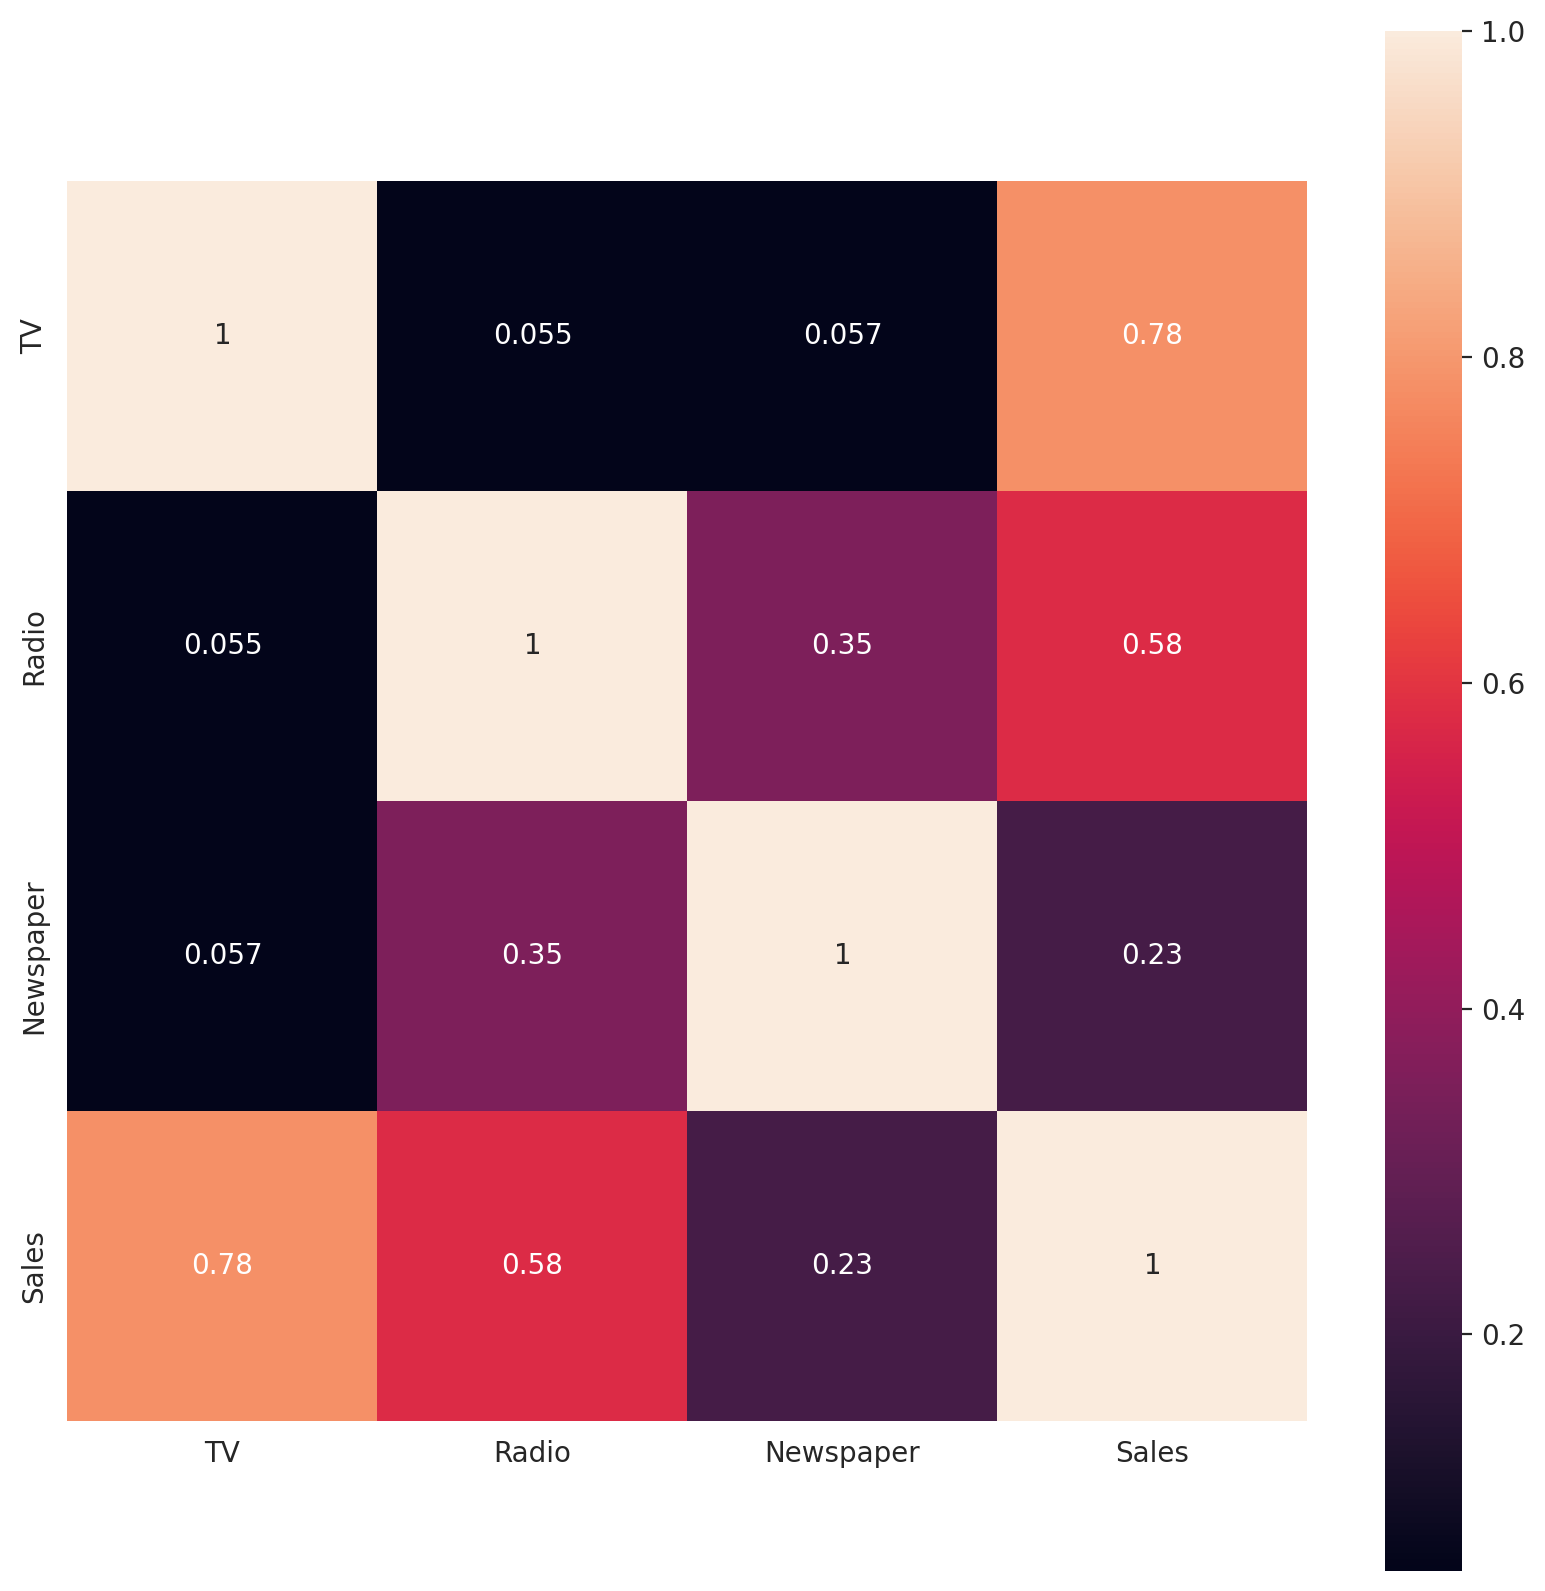

In [34]:
plt.figure(figsize=(10,10))  
p=sns.heatmap(df.corr(), annot=True,square=True)  

##### Buscar la correlación de filas en las que la variable dependiente (Ventas en este caso) no esté involucrada porque si una variable está correlacionada con la variable dependiente, esta sería una buena señal para nuestro modelo. La correlación dentro de las variables dependientes es lo que debemos buscar y evitar. Estos datos no contienen multicolinealidad perfecta entre variables independientes. En caso de que hubiera alguna, intentaríamos eliminar una de las variables correlacionadas según cuál fuera más importante para nuestro modelo de regresión.

Podemos detectar la multicolinealidad utilizando el factor de inflación de la varianza (VIF).

la interpretación de VIF es la siguiente: la raíz cuadrada del VIF de una variable determinada muestra cuánto mayor es el error estándar, en comparación con lo que sería si ese predictor no estuviera correlacionado con las otras características del modelo. 




En el método VIF, elegimos cada función y la retrocedemos contra todas las demás funciones. Para cada regresión, el factor se calcula como:

$$VIF=\frac{1}{1-R^2}$$

Donde, R-cuadrado es el coeficiente de determinación en regresión lineal. Su valor se encuentra entre 0 y 1.

In [35]:
df.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [76]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X= df[['TV', 'Radio', 'Newspaper']]
  
# VIF dataframe
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
  
# calculating VIF for each feature
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
  

print(vif_data)

     feature       VIF
0         TV  2.486772
1      Radio  3.285462
2  Newspaper  3.055245


In [80]:
df.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [84]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df.drop("Sales", axis=1), df.Sales, test_size=0.2, random_state=123 )

In [85]:
X_train.shape

(160, 3)

In [86]:
y_train.shape

(160,)

Reference:
* http://r-statistics.co/Assumptions-of-Linear-Regression.html
* https://www.statisticssolutions.com/assumptions-of-linear-regression/

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=31bf3354-712a-486c-80e4-6fbf4545e8fe' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>